# Sleep summary → Prism (worked example)

Turns the pipeline's **whole-recording** sleep export into GraphPad-Prism tables.
Companion to the by-hour example — same idea, but one number per animal per
recording instead of a time course.

**Input:** `sleep_whole_file.csv` from one or more `sleep_export/` folders. Each row
is one animal × sleep state, standardized over the whole recording.

**Two outputs:**
1. **Summary** (always) — one column per group, animals stacked down each column;
   a Prism *grouped column* table. One sheet per *state × metric*.
2. **Repeated measures** (when you list more than one timepoint) — rows = timepoint,
   columns = animals blocked by group; a Prism *repeated-measures* table.

Metrics map straight from the export: `Fraction` ← `frac_time`,
`Average_Duration` ← `mean_bout_sec`, `Bout_Frequency` ← `bouts_per_hour`.

In [1]:
import pandas as pd
from pathlib import Path
from openpyxl import Workbook

## 1. Point at your export(s)

`EXPORTS` maps a **timepoint label** to a `sleep_export/` folder. Use a single entry
for a one-off summary; add more entries (in the order you want them plotted) to also
get a repeated-measures workbook — the same animals recorded at each timepoint.

In [5]:
EXPORTS = {
    "Stxbp1 cKO": Path("/Users/leahmcintyre/Data/nri/Stxbp1-vglut2_CKO/sleep_export"),
    # Add timepoints for repeated measures, e.g.:
    # "Pre":     Path("/media/matt/Data_A/leah/PHP.eB/PHP_pre/sleep_export"),
    # "6 Weeks": Path("/media/matt/Data_A/leah/PHP.eB/PHP_6_week/sleep_export"),
}

frames = []
for timepoint, export_dir in EXPORTS.items():
    w = pd.read_csv(export_dir / "sleep_whole_file.csv")
    w["timepoint"] = timepoint
    frames.append(w)
whole = pd.concat(frames, ignore_index=True)
whole.head()

,mouse_id,state,frac_time,n_bouts,mean_bout_sec,bouts_per_hour,n_hours,n_days,timepoint
0,JK1873,w,0.554198,804,178.666667,11.166667,72.0,3.0,Stxbp1 cKO
1,JK1873,n,0.434923,804,140.213930,11.166667,72.0,3.0,Stxbp1 cKO
2,JK1873,r,0.010880,48,58.750000,0.666667,72.0,3.0,Stxbp1 cKO
3,JK1876,w,0.542701,1028,136.836576,14.277778,72.0,3.0,Stxbp1 cKO
4,JK1876,n,0.387562,1023,98.197458,14.208333,72.0,3.0,Stxbp1 cKO


Columns of interest: `mouse_id`, `state` (`w`/`n`/`r`), `frac_time`, `n_bouts`,
`mean_bout_sec`, `bouts_per_hour`, plus the `timepoint` we just added.

## 2. Assign each animal to a group

Same as the by-hour example: edit the dict for your project. Keys become the group
blocks in Prism; values are `mouse_id`s exactly as they appear in the export.

In [6]:
groups = {
    'WT': ['JK200', 'JK488', 'JK491', 'JK570', 'JK228', 'JK577'],
    'Flox': ['JK202', 'JK481', 'JK486', 'JK226'],
    'Vglut2-Cre': ['JK1873', 'JK1876', 'JK1928', 'JK1936', 'JK205', 'JK482', 'JK492', 'JK572', 'JK2004', 'JK225', 'JK573'],
    'cHet_Vglut2': ['JK1930', 'JK1931', 'JK1932', 'JK203', 'JK490', 'JK568', 'JK1929', 'JK1935', 'JK2007', 'JK2008','JK2010', 'JK224', 'JK583']
}
whole['mouse_id'] = (whole['mouse_id'].astype('string')
                    .str.replace(r'^Mice-', 'JK', regex=True))

animal_to_group = {a: g for g, animals in groups.items() for a in animals}
whole["group"] = whole["mouse_id"].map(animal_to_group)

unassigned = sorted(whole.loc[whole["group"].isna(), "mouse_id"].unique())
assert not unassigned, f"These animals are not in any group: {unassigned}"
print(f"{len(animal_to_group)} animals assigned across groups: {list(groups)}")

34 animals assigned across groups: ['WT', 'Flox', 'Vglut2-Cre', 'cHet_Vglut2']


## 3. Config + helpers

`METRICS` maps each Prism sheet's metric name to a column in `sleep_whole_file.csv`;
`STATE_DISPLAY` maps the raw state code to its display name. The two writer functions
are the reusable piece — **copy this cell** into your own module to reuse them.

In [ ]:
METRICS = {                       # sheet label -> column in sleep_whole_file.csv
    "Fraction": "frac_time",
    "Average_Duration": "mean_bout_sec",
    "Bout_Frequency": "bouts_per_hour",
}
STATE_DISPLAY = {"w": "Wake", "n": "NREM", "r": "REM"}


def write_summary_workbook(df, out_path, *, group_order, metrics=METRICS, states=STATE_DISPLAY):
    """Prism grouped-column table: one column per group, animal values stacked.

    If an animal has several rows (e.g. multiple timepoints) they are averaged, so
    this collapses to one summary value per animal."""
    wb = Workbook()
    wb.remove(wb.active)
    for label, col in metrics.items():
        for state_key, state_name in states.items():
            sub = df[df["state"] == state_key]
            group_vals = {
                g: sub.loc[sub["group"] == g].groupby("mouse_id")[col].mean().tolist()
                for g in group_order
            }
            ws = wb.create_sheet(f"{state_name}_{label}"[:31])
            for j, g in enumerate(group_order, start=1):
                ws.cell(row=1, column=j, value=g)
                for i, v in enumerate(group_vals[g], start=2):
                    ws.cell(row=i, column=j, value=None if pd.isna(v) else float(v))
    wb.save(out_path)
    return out_path


def write_repeated_measures_workbook(
    df, out_path, *, group_order, timepoint_order, metrics=METRICS, states=STATE_DISPLAY
):
    """Prism repeated-measures table: rows = timepoint, columns = animals blocked by
    group, with a merged group header row above the animal-id row."""
    wb = Workbook()
    wb.remove(wb.active)
    for label, col in metrics.items():
        for state_key, state_name in states.items():
            sub = df[df["state"] == state_key]
            group_animals = {
                g: sorted(sub.loc[sub["group"] == g, "mouse_id"].unique())
                for g in group_order
            }
            # pad shorter groups with blank subcolumns so every group block is the
            # same width in Prism (e.g. WT=5, MUT=6 -> WT gets one blank column)
            max_group_size = max((len(a) for a in group_animals.values()), default=0)
            group_animals = {
                g: (a + [None] * (max_group_size - len(a))) if a else a
                for g, a in group_animals.items()
            }
            wide = sub.pivot_table(index="timepoint", columns="mouse_id", values=col)

            ws = wb.create_sheet(f"{state_name}_{label}"[:31])
            # header rows: merged group label (row 1) over its animal ids (row 2)
            c = 2
            for g in group_order:
                animals = group_animals[g]
                if not animals:
                    continue
                start = c
                for a in animals:
                    ws.cell(row=2, column=c, value=a)
                    c += 1
                ws.cell(row=1, column=start, value=g)
                if c - 1 > start:
                    ws.merge_cells(start_row=1, start_column=start, end_row=1, end_column=c - 1)
            # data rows: one per timepoint
            for r, tp in enumerate(timepoint_order, start=3):
                ws.cell(row=r, column=1, value=tp)
                c = 2
                for g in group_order:
                    for a in group_animals[g]:
                        v = wide.at[tp, a] if (tp in wide.index and a in wide.columns) else None
                        ws.cell(row=r, column=c, value=None if pd.isna(v) else float(v))
                        c += 1
            ws.freeze_panes = "B3"
    wb.save(out_path)
    return out_path

## 4. Write the summary workbook

In [5]:
OUT_DIR = list(EXPORTS.values())[0]  # write next to the first export
summary_path = write_summary_workbook(whole, OUT_DIR / "prism_sleep_summary.xlsx", group_order=list(groups))
print("Wrote", summary_path)

Wrote /media/matt/Data_A/leah/Stxbp1_characterization/sleep_export/prism_sleep_summary.xlsx


## 5. Write the repeated-measures workbook

Only meaningful with more than one timepoint in `EXPORTS`; otherwise this cell just
reports that it was skipped.

In [6]:
timepoint_order = list(EXPORTS)  # plotting order = the order you listed them

if len(timepoint_order) > 1:
    rm_path = write_repeated_measures_workbook(
        whole, OUT_DIR / "prism_sleep_repeated_measures.xlsx",
        group_order=list(groups), timepoint_order=timepoint_order,
    )
    print("Wrote", rm_path)
else:
    print("Only one timepoint in EXPORTS - skipping repeated-measures workbook. "
          "Add more entries to EXPORTS to enable it.")

Only one timepoint in EXPORTS - skipping repeated-measures workbook. Add more entries to EXPORTS to enable it.


Each sheet (`Wake_Fraction`, `NREM_Bout_Frequency`, …) drops straight into Prism:
the **summary** sheets are grouped column tables (paste each group column into a
Prism *Column* table), and the **repeated-measures** sheets are timepoint × animal
tables (paste into a *Grouped* / repeated-measures table).

To reuse this outside the notebook, copy the config + two writer functions from
step 3 into your own `.py` module.

## 6. Plot sleep summary by group

A 3×3 grid of boxplots (with individual animals overlaid) — rows are
`bouts_per_hour` / `mean_bout_sec` / `frac_time`, columns are Wake / NREM / REM.
If an animal has multiple rows (e.g. several timepoints in `EXPORTS`), its values
are averaged first, same as the summary workbook in step 4 — this ignores the
repeated-measures structure from step 5 and treats each animal as a single point.

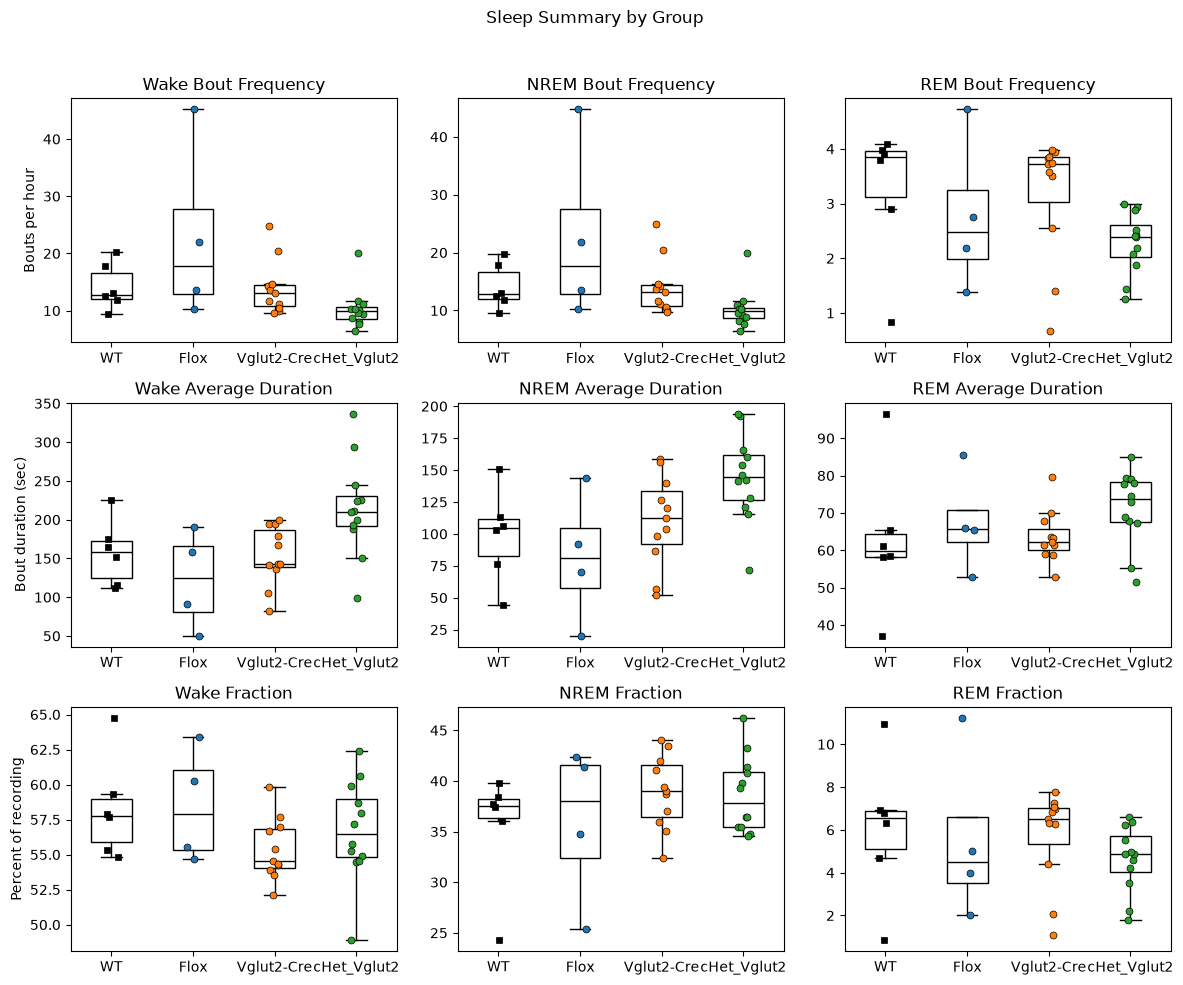

In [8]:
import numpy as np
import matplotlib.pyplot as plt

FIGURE_TITLE = "Sleep Summary by Group"
STATE_ORDER = ["w", "n", "r"]
# (column, title, y-axis label, scale factor for display)
METRIC_ROWS = [
    ("bouts_per_hour", "Bout Frequency", "Bouts per hour", 1),
    ("mean_bout_sec", "Average Duration", "Bout duration (sec)", 1),
    ("frac_time", "Fraction", "Percent of recording", 100),
]
GROUP_STYLE = {
    "WT": dict(color="black", marker="s"),
    "MUT": dict(color="red", marker="o"),
}
group_order = list(groups)

fig, axes = plt.subplots(len(METRIC_ROWS), len(STATE_ORDER), figsize=(12, 10))
fig.suptitle(FIGURE_TITLE)

jitter_rng = np.random.default_rng(0)

for row, (col_name, metric_title, ylabel, scale) in enumerate(METRIC_ROWS):
    for col, state in enumerate(STATE_ORDER):
        ax = axes[row, col]
        sub = whole[whole["state"] == state]
        # one value per animal, averaging across rows (e.g. multiple timepoints)
        per_animal = sub.groupby(["mouse_id", "group"])[col_name].mean().reset_index()
        per_animal[col_name] *= scale

        data = [per_animal.loc[per_animal["group"] == g, col_name].to_numpy() for g in group_order]
        bp = ax.boxplot(data, positions=range(len(group_order)), widths=0.5,
                         showfliers=False, patch_artist=True)
        for patch in bp["boxes"]:
            patch.set_facecolor("white")
        for median in bp["medians"]:
            median.set_color("black")

        for i, (g, vals) in enumerate(zip(group_order, data)):
            style = GROUP_STYLE.get(g, {})
            jitter = jitter_rng.uniform(-0.08, 0.08, size=len(vals))
            ax.scatter(
                np.full(len(vals), i) + jitter, vals,
                color=style.get("color"), marker=style.get("marker", "o"),
                edgecolor="black", linewidths=0.5, zorder=3, s=25,
            )

        ax.set_title(f"{STATE_DISPLAY[state]} {metric_title}")
        ax.set_xticks(range(len(group_order)))
        ax.set_xticklabels(group_order)
        if col == 0:
            ax.set_ylabel(ylabel)

fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()